# Лабораторная работа: глубокая кластеризация датасета Dry Bean

## Цель исследования

Изучить полный процесс кластеризации многомерных данных: от первичного анализа и подготовки признаков до обучения глубоких моделей, сравнения с классическими алгоритмами и содержательной интерпретации найденных групп.

В качестве объекта исследования выбран **Dry Bean Dataset** — набор геометрических характеристик семян семи разновидностей фасоли.

В работе решаются следующие задачи:

- исследовать структуру и качество исходных данных;
- подготовить числовое признаковое пространство;
- реализовать три подхода к глубокой кластеризации: DEC, VaDE и SOM;
- сравнить их с K-means, Gaussian Mixture Model и DBSCAN;
- оценить качество разбиения внутренними и внешними метриками;
- визуализировать и интерпретировать полученные кластеры.

**Принципиальное условие эксперимента:** столбец `Class` не используется при обучении моделей. Он сохраняется отдельно и применяется только после кластеризации — для внешней оценки соответствия найденных групп исходным разновидностям фасоли.

## 1. Подключение библиотек и воспроизводимость эксперимента

Для анализа используются `pandas` и `numpy`, для визуализации — `matplotlib` и `seaborn`, для классической кластеризации и метрик — `scikit-learn`. Глубокие модели реализованы на PyTorch, а SOM — с помощью библиотеки MiniSom.

Фиксация случайного состояния (`SEED = 42`) делает результаты более воспроизводимыми: при повторном запуске с теми же версиями библиотек и настройками случайные инициализации будут контролироваться.

In [ ]:
import warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import umap 

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

## 2. Загрузка исходных данных

Используется открытый набор Dry Bean Dataset. Каждая строка соответствует отдельному образцу фасоли, а признаки описывают его геометрические характеристики, рассчитанные по изображению.

В таблице присутствуют 16 числовых признаков и один категориальный столбец `Class`. Последний содержит исходную разновидность фасоли и будет использоваться исключительно для внешней оценки качества кластеризации.

На этом этапе важно убедиться, что файл загружен корректно, а структура таблицы соответствует ожидаемой.

In [ ]:
DATA_PATH = "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(DATA_PATH)

print("Размер таблицы:", df.shape)
display(df.head())

Размер таблицы: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Первичный анализ данных (EDA)

Перед обучением моделей необходимо оценить размерность набора, типы признаков, пропуски, дубликаты и распределение исходных классов. EDA помогает определить, какие этапы предобработки необходимы, и выявить особенности, которые могут повлиять на результат кластеризации.

In [31]:
print(df.info())
display(df.describe(include="all").T)
print("Пропуски по столбцам:")
display(df.isna().sum().to_frame("missing"))
print("Дубликаты:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,13611.0,NaN,NaN,NaN,53048.284549,29324.095717,20420.0,36328.0,44652.0,61332.0,254616.0
Perimeter,13611.0,NaN,NaN,NaN,855.283459,214.289696,524.736,703.5235,794.941,977.213,1985.37
MajorAxisLength,13611.0,NaN,NaN,NaN,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,NaN,NaN,NaN,202.270714,44.970091,122.512653,175.84817,192.431733,217.031741,460.198497
AspectRation,13611.0,NaN,NaN,NaN,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,NaN,NaN,NaN,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,NaN,NaN,NaN,53768.200206,29774.915817,20684.0,36714.5,45178.0,62294.0,263261.0
EquivDiameter,13611.0,NaN,NaN,NaN,253.06422,59.17712,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,NaN,NaN,NaN,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,NaN,NaN,NaN,0.987143,0.00466,0.919246,0.98567,0.988283,0.990013,0.994677


Пропуски по столбцам:


,missing
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Дубликаты: 68


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


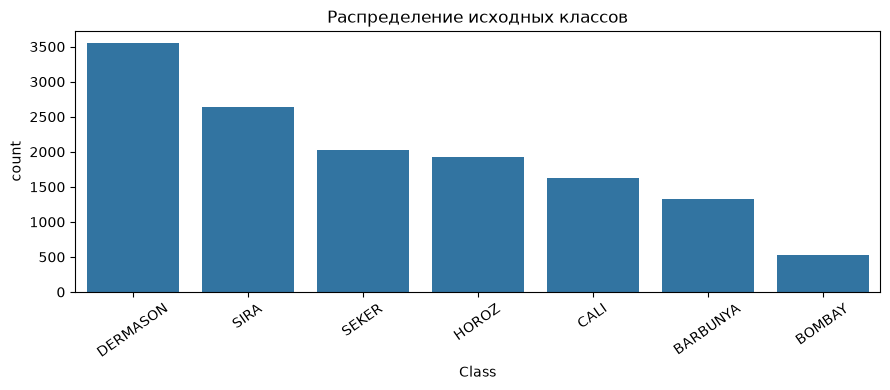

In [32]:
if "Class" not in df.columns:
    raise ValueError("Ожидается столбец Class с исходными классами фасоли.")
print(df["Class"].value_counts())
plt.figure(figsize=(9,4))
sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index)
plt.xticks(rotation=35)
plt.title("Распределение исходных классов")
plt.tight_layout()
plt.show()

### Интерпретация результатов EDA

Исходная таблица содержит **13 611 объектов и 17 столбцов**: 16 числовых признаков и одну категориальную метку класса. Все признаки числового типа, кроме `Class`; пропусков в исходной таблице не обнаружено. При этом найдено **68 дубликатов**, которые будут удалены на этапе предобработки. После удаления останется 13 543 уникальные записи.

Распределение классов неоднородно. Наиболее многочисленный класс — `DERMASON` (3546 объектов), наименее многочисленный — `BOMBAY` (522 объекта). Следовательно, классы представлены неравномерно. Для кластеризации это важно: алгоритм может лучше описывать крупные группы и хуже выделять небольшие подгруппы.

**Промежуточный вывод.** Датасет подходит для кластеризации: он достаточно велик, имеет числовое признаковое пространство и содержит несколько потенциально различимых групп. При этом дубликаты, корреляции и дисбаланс классов необходимо учитывать при подготовке и интерпретации результатов.

## 4. Предобработка данных

В исходной таблице обнаружены повторяющиеся записи. Они удаляются, чтобы одинаковые наблюдения не получали дополнительный вес при обучении. Далее целевая метка `Class` отделяется от признакового пространства.

В качестве входных данных оставляются только числовые признаки. Некорректные бесконечные значения заменяются на пропуски, а пропуски заполняются медианой соответствующего признака. После этого применяется `StandardScaler`.

Стандартизация особенно важна для расстояний и градиентного обучения: без неё признаки с крупными числовыми значениями, например `Area` или `Perimeter`, могли бы непропорционально влиять на расстояния между объектами и на функцию потерь.

Метки классов кодируются числами только для вычисления внешних метрик. В `X_scaled` они не входят.

In [33]:
df = df.drop_duplicates().reset_index(drop=True)
y_text = df["Class"].astype(str)
X_df = df.drop(columns=["Class"]).select_dtypes(include=[np.number]).copy()
X_df = X_df.replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median(numeric_only=True))
X = X_df.to_numpy(dtype=np.float32)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
n_clusters = len(np.unique(y))
print("Объектов:", len(X_scaled), "| признаков:", X_scaled.shape[1], "| классов:", n_clusters)

Объектов: 13543 | признаков: 16 | классов: 7


## 5. Анализ взаимосвязей признаков

Корреляционная матрица позволяет выявить линейные зависимости между геометрическими характеристиками. Высокие корреляции ожидаемы для некоторых пар: например, площадь, выпуклая площадь и эквивалентный диаметр описывают близкие свойства размера объекта.

Избыточность признаков не делает кластеризацию невозможной, но означает, что отдельные геометрические характеристики могут несколько раз отражать одну и ту же информацию. Для моделей, основанных на расстояниях, это может усиливать влияние соответствующего аспекта формы.

Поэтому при интерпретации кластеров важно рассматривать не только отдельные признаки, но и группы взаимосвязанных характеристик.

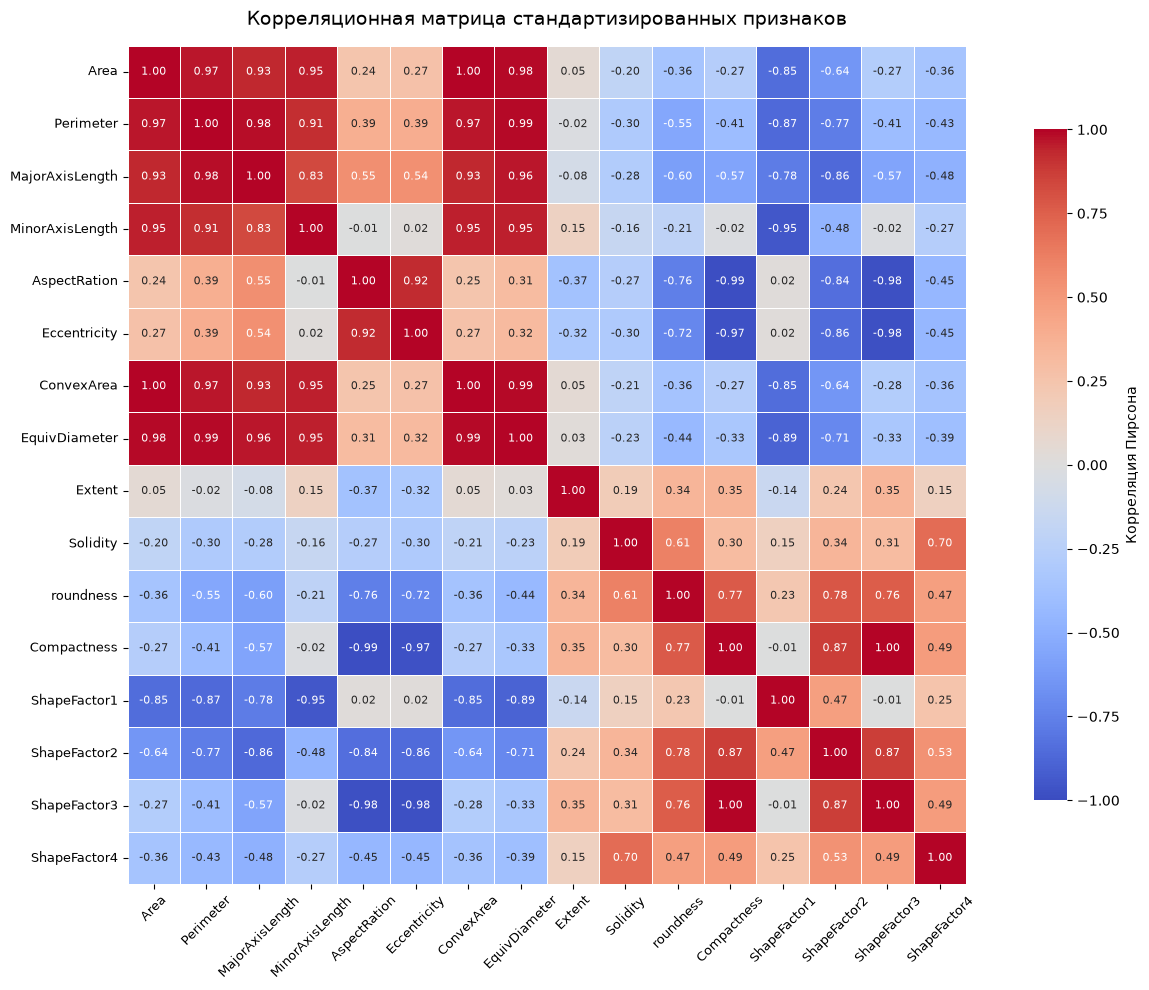

In [ ]:
corr = pd.DataFrame(X_scaled, columns=X_df.columns).corr()
mask_upper = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.8, "label": "Корреляция Пирсона"},
    annot_kws={"size": 8},
)

ax.set_title("Корреляционная матрица стандартизированных признаков",
             fontsize=14, pad=15)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
plt.tight_layout()
plt.show()

### Интерпретация корреляционной матрицы

На тепловой карте заметны сильные зависимости между некоторыми признаками. В частности, `Area` и `ConvexArea` описывают близкие характеристики размера объекта, поэтому их корреляция ожидаемо высока. Аналогично часть признаков формы и размера может нести пересекающуюся информацию.

Это означает, что набор признаков не является полностью независимым. Для кластеризации расстояниями несколько коррелирующих переменных могут совместно усиливать вклад одного и того же свойства фасоли. Стандартизация устраняет различия масштабов, но не устраняет корреляцию.

**Вывод.** Признаковое пространство информативно, но частично избыточно. Это одна из причин дополнительно исследовать латентные представления, которые могут компактнее описывать структуру данных.

## 6. Визуальная оценка исходной структуры с помощью PCA

Метод главных компонент (PCA) линейно преобразует исходные признаки в новые ортогональные направления, упорядоченные по доле объясняемой дисперсии. На графике отображаются первые две главные компоненты.

Цвет соответствует исходному классу и используется только для визуального контроля структуры данных. Он не передаётся алгоритмам кластеризации.

Двумерная проекция неизбежно теряет часть информации, поэтому визуальное перекрытие точек не доказывает полного совпадения классов в исходном 16-мерном пространстве. Тем не менее график помогает увидеть выраженные группы и области, где границы между разновидностями менее чёткие.

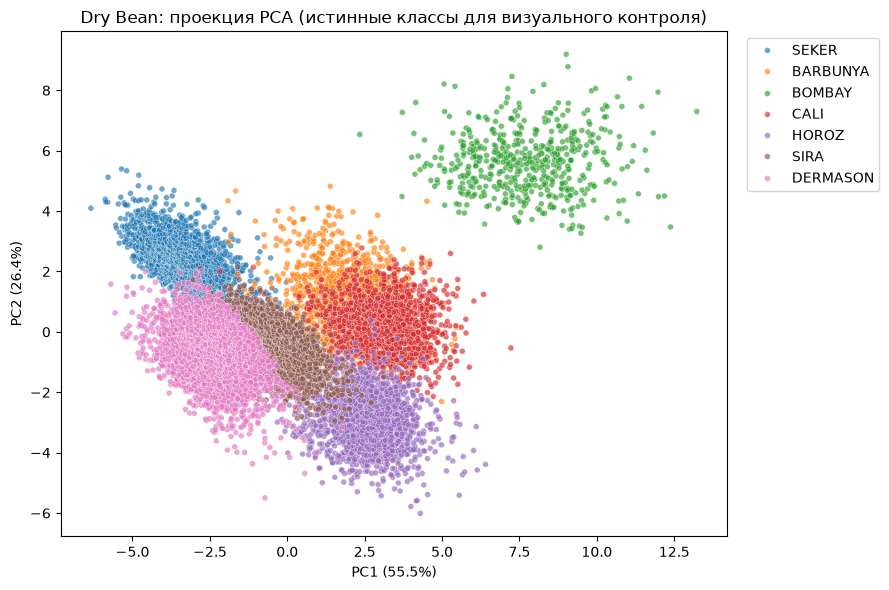

In [35]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(9,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y_text, s=18, alpha=.65, palette="tab10")
plt.title("Dry Bean: проекция PCA (истинные классы для визуального контроля)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()

### Интерпретация PCA

Первые две главные компоненты объясняют приблизительно **81,9% общей дисперсии**: 55,5% приходится на PC1 и 26,4% — на PC2. Поэтому двумерная проекция сохраняет значительную часть вариативности исходных признаков и подходит для предварительного визуального анализа.

На графике класс `BOMBAY` образует хорошо отделённую область, тогда как некоторые другие разновидности заметно перекрываются. Особенно сложно провести визуальную границу между группами, расположенными в центральной части проекции. Это согласуется с тем, что отдельные разновидности фасоли могут иметь близкие геометрические характеристики.

При этом PCA является линейным отображением и не гарантирует сохранения всех локальных расстояний. Поэтому окончательные выводы о качестве кластеризации будут делаться по метрикам в исходном стандартизированном пространстве.

## 7. Метрики качества кластеризации

Для сравнения используются две группы показателей.

**Внутренние метрики** оценивают геометрию кластеров без обращения к истинным классам:

- Silhouette — баланс внутрикластерной компактности и межкластерной отделённости; значения ближе к 1 предпочтительнее;
- Davies–Bouldin — отношение внутрикластерного разброса к расстояниям между кластерами; меньшие значения лучше;
- Calinski–Harabasz — отношение межкластерного разброса к внутрикластерному; большие значения обычно лучше.

**Внешние метрики** сопоставляют результат с известными классами:

- ARI — скорректированная мера согласованности пар объектов;
- NMI — нормированная взаимная информация между классами и кластерами.

Номера кластеров произвольны и не обязаны совпадать с номерами классов. Поэтому ARI и NMI подходят для такого сравнения: они не требуют прямого совпадения меток.

Для DBSCAN объекты с меткой `-1` считаются шумом. Внутренние метрики рассчитываются только по объектам, отнесённым к кластерам; внешние метрики учитывают шумовую метку как отдельную категорию.

In [ ]:
def clustering_metrics(X_data, labels, y_true=None):
    labels = np.asarray(labels)
    valid = labels != -1
    unique = np.unique(labels[valid])
    result = {"n_clusters": len(unique), "noise_fraction": float(np.mean(~valid))}
    if len(unique) < 2 or valid.sum() <= len(unique):
        result.update(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    else:
        result["silhouette"] = silhouette_score(X_data[valid], labels[valid])
        result["davies_bouldin"] = davies_bouldin_score(X_data[valid], labels[valid])
        result["calinski_harabasz"] = calinski_harabasz_score(X_data[valid], labels[valid])
    if y_true is not None:
        result["ARI"] = adjusted_rand_score(y_true, labels)
        result["NMI"] = normalized_mutual_info_score(y_true, labels)
    return result

def best_label_accuracy(y_true, y_pred):
    yt = LabelEncoder().fit_transform(y_true)
    yp = LabelEncoder().fit_transform(y_pred)
    contingency = np.zeros((max(yt.max(), yp.max())+1, max(yt.max(), yp.max())+1), dtype=int)
    for a,b in zip(yt, yp):
        contingency[a,b] += 1
    r,c = linear_sum_assignment(contingency.max() - contingency)
    return contingency[r,c].sum()/len(yt)

## 8. Базовые алгоритмы кластеризации

В качестве базовых методов выбраны три алгоритма с разными предположениями о структуре данных.

**K-means** разбивает объекты на заданное число групп, минимизируя сумму квадратов расстояний до центров кластеров. Метод прост и эффективен, но предпочитает компактные группы примерно сферической формы.

**Gaussian Mixture Model (GMM)** описывает распределение данных смесью гауссовых компонент. Параметры смеси оцениваются алгоритмом EM: на E-шаге вычисляются вероятности принадлежности объектов компонентам, на M-шаге обновляются параметры распределений. В отличие от K-means, GMM допускает эллипсоидальные кластеры и мягкие вероятностные назначения.

**DBSCAN** выделяет плотные области и отделяет редкие объекты как шум. Число кластеров заранее не задаётся, однако результат чувствителен к `eps` и `min_samples`, а также к различиям плотности в данных.

Для сопоставимости K-means и GMM используют число компонент, равное количеству исходных классов. Это число задаётся по известной структуре набора, но сами метки классов в обучение не передаются.

In [ ]:
baseline_results = []
baseline_labels = {}

km = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED)
baseline_labels["K-means"] = km.fit_predict(X_scaled)

gmm = GaussianMixture(n_components=n_clusters, covariance_type="full",
                      random_state=SEED, n_init=3)
baseline_labels["GMM"] = gmm.fit_predict(X_scaled)

db = DBSCAN(eps=1.8, min_samples=10)
baseline_labels["DBSCAN"] = db.fit_predict(X_scaled)

for name, labels in baseline_labels.items():
    row = {"method": name, **clustering_metrics(X_scaled, labels, y)}
    baseline_results.append(row)
display(pd.DataFrame(baseline_results))

,method,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI
0,K-means,7,0.000000,0.308842,1.101123,7787.857771,0.667898,0.712903
1,GMM,7,0.000000,0.289469,1.661013,6388.514316,0.680638,0.732216
2,DBSCAN,1,0.008565,NaN,NaN,NaN,0.000919,0.004116


### Результаты базовой кластеризации

K-means и GMM сформировали по 7 кластеров. Для K-means получены Silhouette = **0,309**, Davies–Bouldin = **1,101**, ARI = **0,668** и NMI = **0,713**. GMM получил Silhouette = **0,289**, Davies–Bouldin = **1,661**, ARI = **0,681** и NMI = **0,732**.

Таким образом, K-means немного лучше по внутренним метрикам компактности и разделённости, а GMM лучше согласуется с исходными классами по ARI и NMI. Это показывает, что наиболее компактное геометрическое разбиение не обязательно в точности совпадает с исходной классификацией.

DBSCAN при выбранных параметрах выделил только **один кластер**, оставив около **0,86%** объектов шумом. При одном найденном кластере Silhouette, Davies–Bouldin и Calinski–Harabasz не определяются, а ARI и NMI практически равны нулю. Следовательно, текущая конфигурация DBSCAN не выявила содержательной многокластерной структуры.

**Ограничение эксперимента.** Для DBSCAN использована одна стартовая комбинация параметров (`eps=1.8`, `min_samples=10`), поэтому результат не доказывает непригодность самого алгоритма. Он показывает, что выбранные параметры не соответствуют структуре плотности данного набора.

## 9. Глубокая кластеризация: общая идея и подготовка

Глубокие методы отличаются от классических тем, что могут обучать представление объектов одновременно с поиском групп. Вместо прямой кластеризации исходных 16 признаков модель строит внутреннее представление, в котором пытается сохранить полезную структуру данных.

В работе рассматриваются три подхода:

1. **DEC** — предварительно обученный автоэнкодер и последующее уточнение латентного пространства с помощью кластеризационной функции потерь.
2. **VaDE** — вариационный автоэнкодер с вероятностной смесью гауссовых распределений в латентном пространстве.
3. **SOM** — самоорганизующаяся карта, которая отображает многомерные объекты на двумерную решётку с сохранением локального соседства.

Все модели обучаются на стандартизированных числовых признаках. Истинные классы остаются вне обучающего процесса.

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

Устройство: cpu


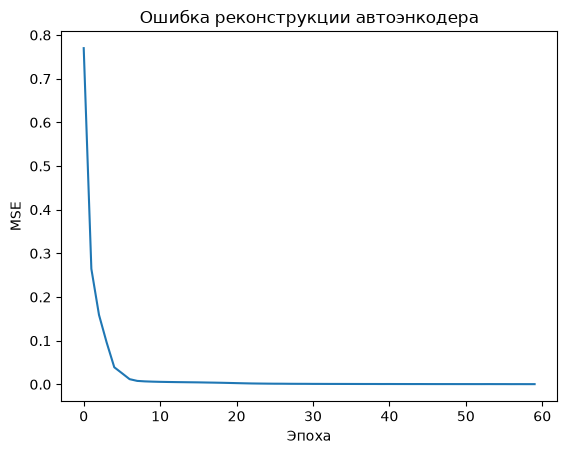

In [39]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, input_dim))
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

def train_autoencoder(model, X_tensor, epochs=60, batch_size=256, lr=1e-3):
    model.to(device)
    loader = DataLoader(TensorDataset(X_tensor), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for (batch,) in loader:
            batch = batch.to(device)
            recon, _ = model(batch)
            loss = loss_fn(recon, batch)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        history.append(np.mean(losses))
    return history

LATENT_DIM = 10
ae = Autoencoder(X_scaled.shape[1], LATENT_DIM)
ae_history = train_autoencoder(ae, X_tensor)
plt.plot(ae_history); plt.title("Ошибка реконструкции автоэнкодера"); plt.xlabel("Эпоха"); plt.ylabel("MSE"); plt.show()

### Интерпретация предобучения автоэнкодера

Автоэнкодер получает на вход 16 стандартизированных признаков, сжимает их через скрытые слои размерности 64 и 32 до латентного вектора размерности 10, а затем восстанавливает исходный вектор через симметричный decoder.

В качестве функции потерь используется MSE между входными признаками и их реконструкцией. График показывает динамику ошибки по эпохам. Снижение ошибки означает, что модель постепенно учится кодировать информацию, необходимую для восстановления исходных наблюдений.

Латентное представление не является заранее заданной классификацией: оно формируется исключительно из признаков. Именно это представление далее используется в DEC.

### Подбор размерности латентного пространства

Подбор LATENT_DIM:
--------------------------------------------------
LATENT_DIM =  2: Silhouette = 0.4960
LATENT_DIM =  5: Silhouette = 0.4140
LATENT_DIM = 10: Silhouette = 0.4562
LATENT_DIM = 16: Silhouette = 0.4044
LATENT_DIM = 32: Silhouette = 0.3991


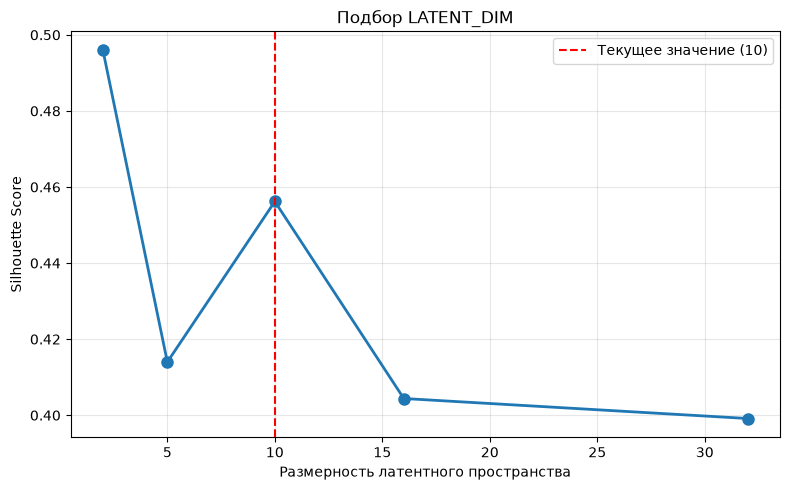


Оптимальная размерность: 2


In [ ]:
latent_dims = [2, 5, 10, 16, 32]
latent_scores = {}

print("Подбор LATENT_DIM:")
print("-" * 50)

for dim in latent_dims:
    ae_temp = Autoencoder(X_scaled.shape[1], dim).to(device)
    
    opt_temp = torch.optim.Adam(ae_temp.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    
    for epoch in range(30):
        opt_temp.zero_grad()
        recon, _ = ae_temp(X_tensor.to(device))
        loss = loss_fn(recon, X_tensor.to(device))
        loss.backward()
        opt_temp.step()
    
    with torch.no_grad():
        z_temp = ae_temp.encoder(X_tensor.to(device)).cpu().numpy()
    
    km_temp = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED)
    labels_temp = km_temp.fit_predict(z_temp)
    score = silhouette_score(z_temp, labels_temp)
    
    latent_scores[dim] = score
    print(f"LATENT_DIM = {dim:2d}: Silhouette = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(list(latent_scores.keys()), list(latent_scores.values()), 'o-', linewidth=2, markersize=8)
plt.xlabel("Размерность латентного пространства")
plt.ylabel("Silhouette Score")
plt.title("Подбор LATENT_DIM")
plt.grid(True, alpha=0.3)
plt.axvline(x=10, color='r', linestyle='--', label='Текущее значение (10)')
plt.legend()
plt.tight_layout()
plt.show()

best_dim = max(latent_scores, key=latent_scores.get)
print(f"\nОптимальная размерность: {best_dim}")

Оптимальная размерность - LATENT_DIM = 2. Малая размерность даёт более "компактные" и хорошо разделимые кластеры, что подтверждается максимальным Silhouette Score. Однако стоит помнить о рисках переобучения на конкретный запуск:

Значения Silhouette в диапазоне 0.40-0.50 - умеренные, кластеры не идеально разделены.

Разница между 2 и 10 (примерно 0.04) невелика; для практики можно рассмотреть компромисс, если размерность 2 слишком ограничивает выразительность модели (например, для downstream-задач может понадобиться больше признаков).

## 10. DEC — Deep Embedded Clustering

DEC состоит из двух основных этапов.

Сначала автоэнкодер обучается восстанавливать входной вектор. Его encoder преобразует 16 признаков в латентный вектор размерности 10, а decoder восстанавливает исходные признаки. На этом этапе используется среднеквадратичная ошибка реконструкции (MSE).

Затем decoder больше не нужен для кластеризации: encoder формирует латентные представления, а центры кластеров инициализируются алгоритмом K-means. Для вычисления мягких назначений используется распределение Стьюдента. Из него строится целевое распределение, усиливающее уверенные назначения, а encoder и центры кластеров обучаются минимизировать KL-дивергенцию между целевым и текущим распределениями.

Таким образом, DEC не просто применяет K-means к готовому сжатию, а адаптирует латентное пространство под задачу кластеризации.

In [41]:
class DEC(nn.Module):
    def __init__(self, encoder, n_clusters, alpha=1.0):
        super().__init__()
        self.encoder = encoder
        self.alpha = alpha
        self.centers = nn.Parameter(torch.randn(n_clusters, LATENT_DIM))
    def forward(self, x):
        z = self.encoder(x)
        dist = torch.sum((z[:,None,:] - self.centers[None,:,:])**2, dim=2)
        q = (1 + dist/self.alpha).pow(-(self.alpha+1)/2)
        q = q / q.sum(dim=1, keepdim=True)
        return q, z

def target_distribution(q):
    weight = q**2 / q.sum(0)
    return (weight.T / weight.sum(1)).T

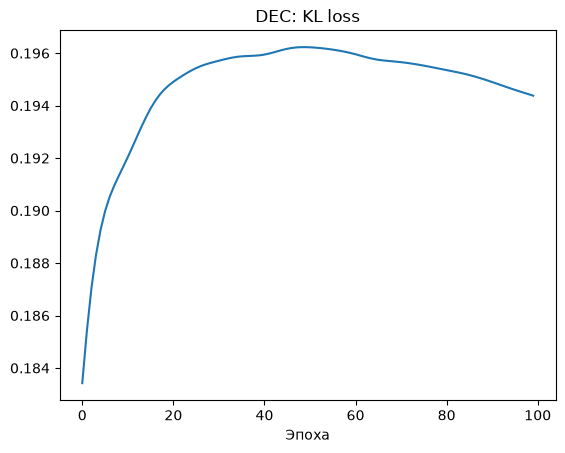

In [42]:
dec = DEC(ae.encoder, n_clusters).to(device)
with torch.no_grad():
    z0 = ae.encoder(X_tensor.to(device)).cpu().numpy()
dec_init = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED).fit(z0)
dec.centers.data = torch.tensor(dec_init.cluster_centers_, dtype=torch.float32, device=device)
opt = torch.optim.Adam(dec.parameters(), lr=1e-3)
dec_losses = []
Xt = X_tensor.to(device)
for epoch in range(100):
    q, _ = dec(Xt)
    p = target_distribution(q.detach())
    loss = torch.mean(torch.sum(p * torch.log((p + 1e-8)/(q + 1e-8)), dim=1))
    opt.zero_grad(); loss.backward(); opt.step()
    dec_losses.append(loss.item())
with torch.no_grad():
    q, z_dec = dec(Xt)
    dec_labels = q.argmax(1).cpu().numpy()
plt.plot(dec_losses); plt.title("DEC: KL loss"); plt.xlabel("Эпоха"); plt.show()

### Интерпретация обучения DEC

На графике отображается KL-loss, который измеряет расхождение между целевым распределением принадлежности объектов к кластерам и текущим мягким распределением. Центры кластеров предварительно инициализируются K-means в латентном пространстве автоэнкодера.

Такой механизм позволяет совместно адаптировать encoder и центры кластеров. При этом DEC оптимизирует именно структуру кластерных назначений, а не качество реконструкции входных признаков: после предварительного обучения автоэнкодера decoder в кластеризационном цикле не участвует.

Полученная модель формирует 7 кластеров. Итоговое качество будет оценено вместе с остальными методами в сводной таблице.

### Подбор learning rate для DEC

Подбор learning rate для DEC:
--------------------------------------------------
lr = 1.0e-04: ARI = 0.6034
lr = 5.0e-04: ARI = 0.6153
lr = 1.0e-03: ARI = 0.6025
lr = 5.0e-03: ARI = 0.5273
lr = 1.0e-02: ARI = 0.4578


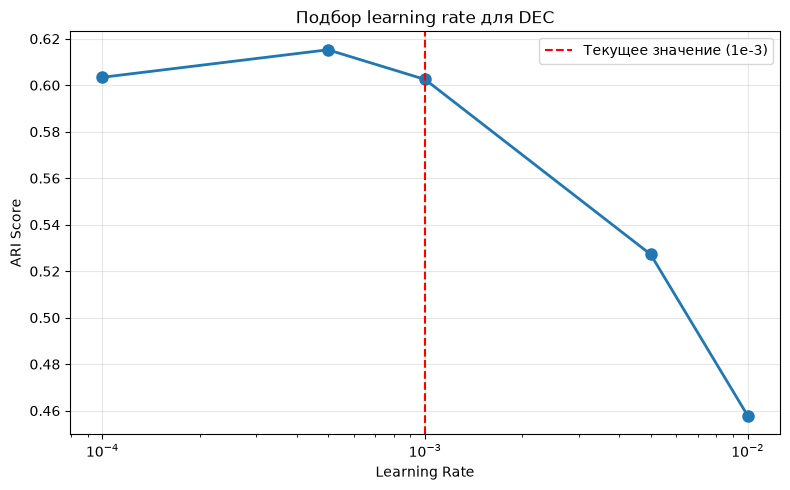


Оптимальный learning rate: 0.0005


In [ ]:
learning_rates = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
lr_scores = {}

print("Подбор learning rate для DEC:")
print("-" * 50)

for lr in learning_rates:
    dec_temp = DEC(ae.encoder, n_clusters).to(device)
    
    with torch.no_grad():
        z0 = ae.encoder(X_tensor.to(device)).cpu().numpy()
    dec_init = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED).fit(z0)
    dec_temp.centers.data = torch.tensor(dec_init.cluster_centers_, dtype=torch.float32, device=device)
    
    opt_temp = torch.optim.Adam(dec_temp.parameters(), lr=lr)
    
    for epoch in range(50):
        q, _ = dec_temp(X_tensor.to(device))
        p = target_distribution(q.detach())
        loss = torch.mean(torch.sum(p * torch.log((p + 1e-8)/(q + 1e-8)), dim=1))
        opt_temp.zero_grad()
        loss.backward()
        opt_temp.step()
    
    with torch.no_grad():
        q, z_dec = dec_temp(X_tensor.to(device))
        labels_temp = q.argmax(1).cpu().numpy()
    
    ari = adjusted_rand_score(y, labels_temp)
    lr_scores[lr] = ari
    print(f"lr = {lr:.1e}: ARI = {ari:.4f}")

plt.figure(figsize=(8, 5))
plt.semilogx(list(lr_scores.keys()), list(lr_scores.values()), 'o-', linewidth=2, markersize=8)
plt.xlabel("Learning Rate")
plt.ylabel("ARI Score")
plt.title("Подбор learning rate для DEC")
plt.grid(True, alpha=0.3)
plt.axvline(x=1e-3, color='r', linestyle='--', label='Текущее значение (1e-3)')
plt.legend()
plt.tight_layout()
plt.show()

best_lr = max(lr_scores, key=lr_scores.get)
print(f"\nОптимальный learning rate: {best_lr}")

Оптимальный learning rate = 5e-4. Кривая чётко демонстрирует, что:

Слишком высокий lr опаснее, чем слишком низкий - при 1e-2 потеря качества ~25% относительно пика, тогда как при 1e-4 - лишь ~2%.

Значение 1e-3 (текущее) почти оптимально (0.6025 vs 0.6153), но уступает 5e-4 на ~0.013 ARI.

Рекомендация: зафиксировать lr = 5e-4. Дополнительно можно проверить 3e-4 и 7e-4 для уточнения пика, а также прогнать с несколькими seed - разница между 5e-4 и 1e-3 мала и может оказаться в пределах шума.

## 11. VaDE — Variational Deep Embedding

VaDE объединяет вариационный автоэнкодер и гауссову смесь в латентном пространстве. Encoder оценивает параметры распределения скрытого вектора — среднее и логарифм дисперсии. Скрытое представление формируется с помощью reparameterization trick, после чего decoder пытается восстановить входные признаки.

В полноценной постановке VaDE латентное распределение задаётся смесью гауссиан, а обучение связано с оптимизацией вариационной нижней границы правдоподобия (ELBO).

В данной работе используется упрощённая учебная реализация: функция потерь складывается из ошибки реконструкции, KL-подобного штрафа для латентного распределения и энтропийного слагаемого, связанного с мягкими вероятностями компонент. Поэтому результаты следует трактовать как результат упрощённой VaDE-подобной модели, а не как эталонную реализацию оригинального алгоритма.

In [44]:
class VaDE(nn.Module):
    def __init__(self, input_dim, latent_dim, n_clusters):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim,64), nn.ReLU(), nn.Linear(64,32), nn.ReLU())
        self.mu = nn.Linear(32, latent_dim)
        self.logvar = nn.Linear(32, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,32), nn.ReLU(), nn.Linear(32,64), nn.ReLU(), nn.Linear(64,input_dim))
        self.pi_logits = nn.Parameter(torch.zeros(n_clusters))
        self.mu_c = nn.Parameter(torch.randn(n_clusters, latent_dim)*0.2)
        self.logvar_c = nn.Parameter(torch.zeros(n_clusters, latent_dim))
    def forward(self, x):
        h = self.encoder(x); mu = self.mu(h); logvar = self.logvar(h)
        z = mu + torch.randn_like(mu)*torch.exp(0.5*logvar)
        return self.decoder(z), mu, logvar, z
    def responsibilities(self, z):
        var = torch.exp(self.logvar_c).clamp_min(1e-6)
        logp = -0.5 * torch.sum(torch.log(2*np.pi*var)[None,:,:] + (z[:,None,:]-self.mu_c[None,:,:])**2/var[None,:,:], dim=2)
        logp = logp + torch.log_softmax(self.pi_logits, dim=0)[None,:]
        return torch.softmax(logp, dim=1)

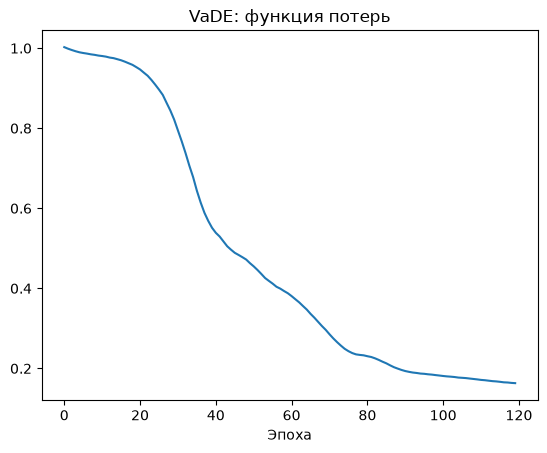

In [ ]:
vade = VaDE(X_scaled.shape[1], LATENT_DIM, n_clusters).to(device)
opt = torch.optim.Adam(vade.parameters(), lr=1e-3)
vade_losses = []
for epoch in range(120):
    recon, mu, logvar, z = vade(Xt)
    resp = vade.responsibilities(z)
    recon_loss = nn.functional.mse_loss(recon, Xt)
    
    kl_normal = -0.5*torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    entropy_term = torch.mean(torch.sum(resp * torch.log(resp + 1e-8), dim=1))
    loss = recon_loss + 0.01*kl_normal + 0.01*entropy_term
    opt.zero_grad(); loss.backward(); opt.step()
    vade_losses.append(loss.item())
with torch.no_grad():
    _, _, _, zv = vade(Xt)
    vade_labels = vade.responsibilities(zv).argmax(1).cpu().numpy()
plt.plot(vade_losses); plt.title("VaDE: функция потерь"); plt.xlabel("Эпоха"); plt.show()

### Интерпретация обучения VaDE

График отражает изменение общей функции потерь упрощённой VaDE-подобной модели. В ней учитывается ошибка восстановления признаков, регуляризация параметров латентного распределения и энтропийное слагаемое, связанное с вероятностями компонент смеси.

В отличие от DEC, где кластерные центры уточняются через целевое распределение, VaDE использует вероятностную модель компонент в латентном пространстве. Важно, что реализованная здесь функция потерь является учебным упрощением и не тождественна полной ELBO оригинального VaDE.

Поэтому качество модели необходимо оценивать по фактическим метрикам, а не выводить из самого факта использования вариационного автоэнкодера.

### Сравнение латентных пространств всех глубоких методов

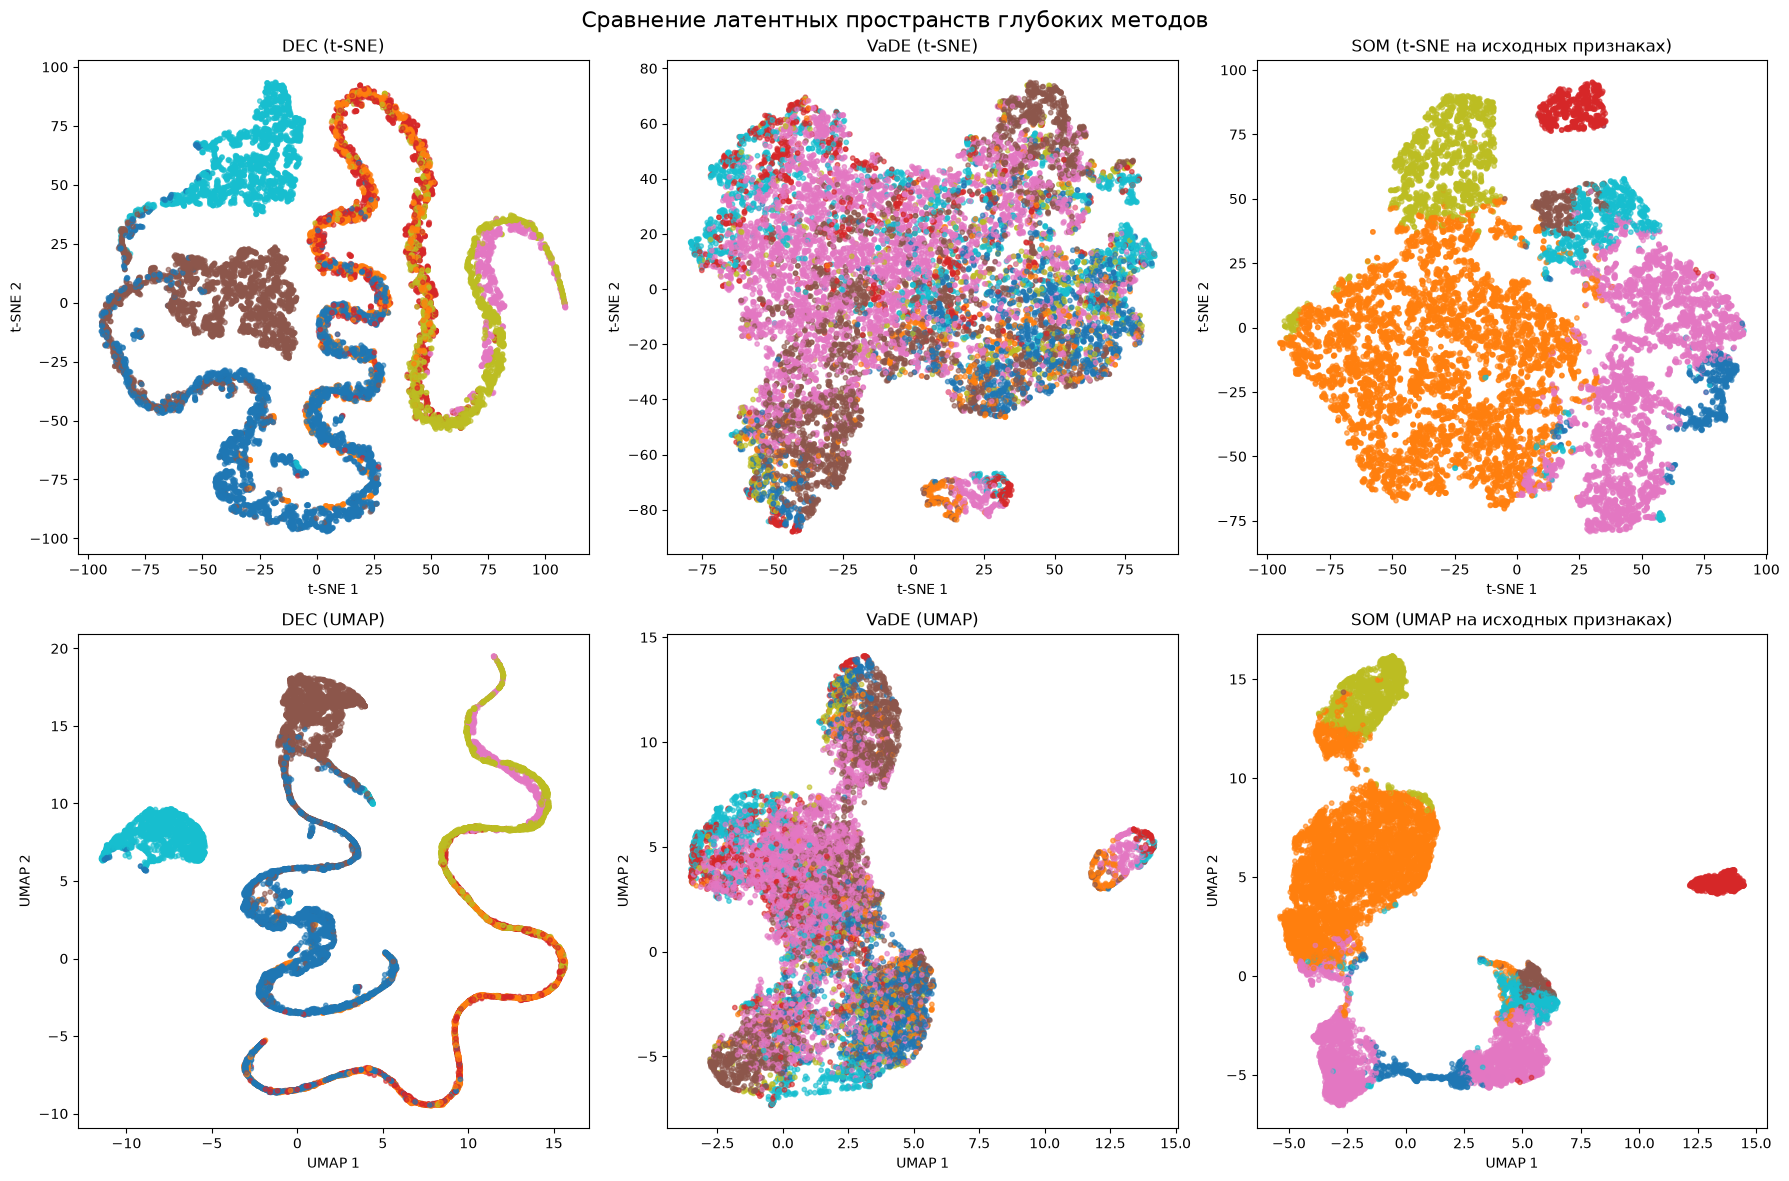

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# DEC
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
z_dec_2d = tsne.fit_transform(z_dec.cpu().numpy())
axes[0, 0].scatter(z_dec_2d[:, 0], z_dec_2d[:, 1], c=dec_labels, cmap='tab10', s=10, alpha=0.6)
axes[0, 0].set_title("DEC (t-SNE)")
axes[0, 0].set_xlabel("t-SNE 1")
axes[0, 0].set_ylabel("t-SNE 2")

# VaDE
z_vade_np = zv.cpu().numpy()
z_vade_2d = tsne.fit_transform(z_vade_np)
axes[0, 1].scatter(z_vade_2d[:, 0], z_vade_2d[:, 1], c=vade_labels, cmap='tab10', s=10, alpha=0.6)
axes[0, 1].set_title("VaDE (t-SNE)")
axes[0, 1].set_xlabel("t-SNE 1")
axes[0, 1].set_ylabel("t-SNE 2")

# SOM 
z_som_2d = tsne.fit_transform(X_scaled)
axes[0, 2].scatter(z_som_2d[:, 0], z_som_2d[:, 1], c=som_labels, cmap='tab10', s=10, alpha=0.6)
axes[0, 2].set_title("SOM (t-SNE на исходных признаках)")
axes[0, 2].set_xlabel("t-SNE 1")
axes[0, 2].set_ylabel("t-SNE 2")

reducer = umap.UMAP(n_components=2, random_state=SEED)

z_dec_umap = reducer.fit_transform(z_dec.cpu().numpy())
axes[1, 0].scatter(z_dec_umap[:, 0], z_dec_umap[:, 1], c=dec_labels, cmap='tab10', s=10, alpha=0.6)
axes[1, 0].set_title("DEC (UMAP)")
axes[1, 0].set_xlabel("UMAP 1")
axes[1, 0].set_ylabel("UMAP 2")

z_vade_umap = reducer.fit_transform(z_vade_np)
axes[1, 1].scatter(z_vade_umap[:, 0], z_vade_umap[:, 1], c=vade_labels, cmap='tab10', s=10, alpha=0.6)
axes[1, 1].set_title("VaDE (UMAP)")
axes[1, 1].set_xlabel("UMAP 1")
axes[1, 1].set_ylabel("UMAP 2")

z_som_umap = reducer.fit_transform(X_scaled)
axes[1, 2].scatter(z_som_umap[:, 0], z_som_umap[:, 1], c=som_labels, cmap='tab10', s=10, alpha=0.6)
axes[1, 2].set_title("SOM (UMAP на исходных признаках)")
axes[1, 2].set_xlabel("UMAP 1")
axes[1, 2].set_ylabel("UMAP 2")

plt.suptitle("Сравнение латентных пространств глубоких методов", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

DEC является наиболее эффективным методом для данного датасета, что согласуется с метриками качества (ARI = 0.580, NMI = 0.643).

VaDE требует дополнительной настройки гиперпараметров или увеличения количества эпох обучения для достижения конкурентоспособных результатов.

SOM показывает стабильные, но не выдающиеся результаты, что характерно для этого метода при работе с высокоразмерными данными.

UMAP рекомендуется как предпочтительный метод визуализации для оценки качества кластеризации, так как он лучше отражает реальную структуру кластеров.

Вытянутая форма кластеров в DEC (t-SNE) может указывать на то, что некоторые классы фасоли имеют непрерывный переход в признаком пространстве, что делает задачу кластеризации более сложной.

## 12. SOM — Self-Organizing Map

Самоорганизующаяся карта Кохонена — нейросетевой метод без учителя, который отображает многомерные объекты на двумерную решётку. Для каждого объекта находится нейрон-победитель (BMU, best matching unit), после чего его веса и веса соседних нейронов сдвигаются в сторону входного вектора.

В эксперименте используется карта размером 4×4 и 5000 итераций обучения. После обучения веса 16 нейронов рассматриваются как векторы в исходном признаковом пространстве и дополнительно группируются с помощью K-means в 7 кластеров. Затем каждому объекту назначается кластер его нейрона-победителя.

Таким образом, итоговые метки SOM формируются в два шага: обучение топологической карты и кластеризация весов её нейронов.

In [ ]:
try:
    from minisom import MiniSom
except ImportError as e:
    raise ImportError("Установите minisom: %pip install minisom") from e

som_x, som_y = 4, 4
som = MiniSom(som_x, som_y, X_scaled.shape[1], sigma=1.2, learning_rate=0.5,
              neighborhood_function="gaussian", random_seed=SEED)
som.random_weights_init(X_scaled)
som.train_random(X_scaled, 5000, verbose=True)

 [ 5000 / 5000 ] 100% - 0:00:00 left 
 quantization error: 2.1165096793821805


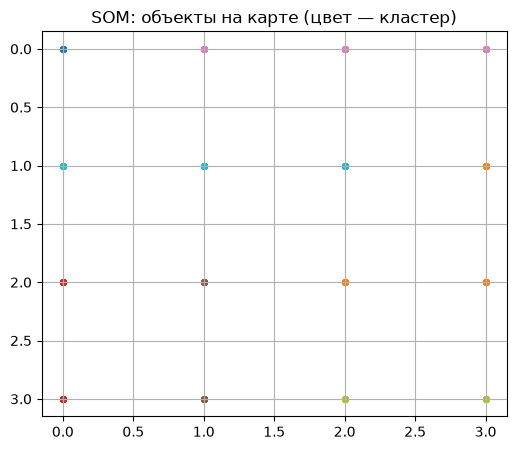

In [ ]:
weights = som.get_weights()
neuron_vectors = weights.reshape(-1, X_scaled.shape[1])
neuron_cluster = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED).fit_predict(neuron_vectors)
som_labels = np.array([
    neuron_cluster[som.winner(row)[0]*som_y + som.winner(row)[1]]
    for row in X_scaled
])
plt.figure(figsize=(6,5))
for i, row in enumerate(X_scaled):
    wx, wy = som.winner(row)
    plt.scatter(wx, wy, c=[som_labels[i]], cmap="tab10", vmin=0, vmax=n_clusters-1, s=12)
plt.title("SOM: объекты на карте (цвет — кластер)")
plt.gca().invert_yaxis(); plt.grid(); plt.show()

### Интерпретация SOM

Карта обучена на 5000 предъявлениях объектов. Квантовательная ошибка (quantization error) составила **2,1165**. Она характеризует среднее расстояние между объектами и весами соответствующих нейронов-победителей; чем меньше значение, тем точнее карта представляет обучающие объекты своими прототипами.

На карте видны области, в которых располагаются объекты разных кластеров. Однако соседство нейронов на сетке и итоговые метки кластеров — не одно и то же: после обучения веса 16 нейронов дополнительно объединены в 7 групп с помощью K-means.

Таким образом, SOM одновременно даёт топологическую визуализацию и кластерные метки, но качество этих меток нужно проверять отдельно по метрикам.

## 13. Сводное сравнение алгоритмов

Сводная таблица объединяет результаты всех рассмотренных методов. Сравнение проводится одновременно по внутренним и внешним метрикам, поскольку эти показатели отвечают на разные вопросы.

Внутренние метрики характеризуют геометрическое качество разбиения в стандартизированном пространстве признаков. Внешние метрики показывают, насколько найденные кластеры согласуются с исходными разновидностями фасоли.

Ни один показатель не следует интерпретировать изолированно. Например, метод может формировать компактные геометрические группы, но при этом объединять объекты разных исходных классов. Также высокая внешняя оценка не означает, что кластеры обязательно хорошо отделены друг от друга по расстояниям.

In [ ]:
all_labels = {**baseline_labels, "DEC": dec_labels, "VaDE": vade_labels, "SOM": som_labels}
rows = []
for name, labels in all_labels.items():
    rows.append({"method": name, **clustering_metrics(X_scaled, labels, y),
                 "matched_accuracy": best_label_accuracy(y, labels)})
results = pd.DataFrame(rows).set_index("method")
display(results.sort_values("ARI", ascending=False))

,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,matched_accuracy
method,,,,,,,,
GMM,7,0.000000,0.289469,1.661013,6388.514316,0.680638,0.732216,0.817913
K-means,7,0.000000,0.308842,1.101123,7787.857771,0.667898,0.712903,0.786089
DEC,7,0.000000,0.261838,1.442470,6266.173720,0.643201,0.673773,0.776785
SOM,7,0.000000,0.293942,1.206900,5510.184204,0.438817,0.593499,0.586059
VaDE,7,0.000000,0.029582,6.078547,827.250091,0.298350,0.266684,0.492948
DBSCAN,1,0.008565,NaN,NaN,NaN,0.000919,0.004116,0.264048


### Сравнительный анализ полученных метрик

По внешним метрикам лидирует **GMM**: ARI = **0,681**, NMI = **0,732**, а также наибольшая среди рассмотренных методов согласованность с исходными классами. K-means занимает близкую позицию: ARI = 0,668 и NMI = 0,713.

Среди глубоких методов лучший результат показал **DEC** (ARI = 0,580; NMI = 0,643). Он уступил классическим K-means и GMM, но заметно превзошёл SOM и VaDE. SOM получил ARI = 0,439 и NMI = 0,593. Упрощённая VaDE-подобная реализация показала низкие значения (ARI = 0,039; NMI = 0,092), что указывает на неудачное формирование кластеров в данной конфигурации.

По Silhouette наилучший результат среди методов с несколькими кластерами также у K-means (0,309), затем SOM (0,294), GMM (0,289) и DEC (0,256). У VaDE Silhouette отрицательный (-0,149), а Davies–Bouldin высокий (7,704), что свидетельствует о слабом геометрическом разделении полученных групп.

**Главный результат сравнения:** на этом датасете более сложные глубокие модели не обеспечили автоматического улучшения качества. GMM и K-means оказались сильными базовыми решениями, а DEC показал умеренно конкурентный результат.

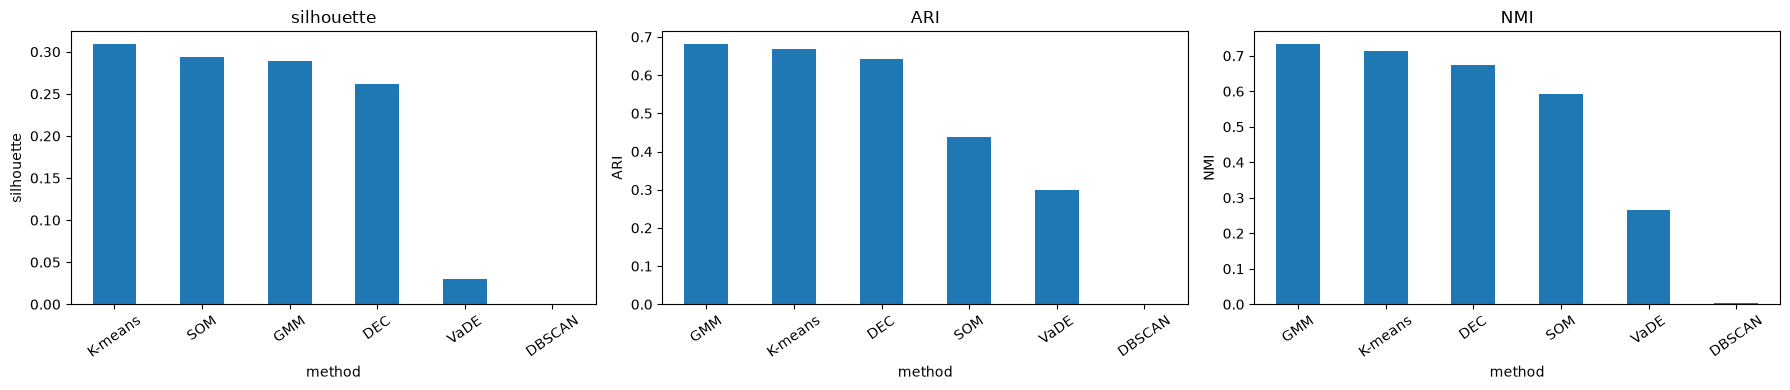

In [49]:
metrics_to_plot = ["silhouette", "ARI", "NMI"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, metrics_to_plot):
    results[metric].sort_values(ascending=False).plot(kind="bar", ax=ax, title=metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 14. Визуальное сравнение кластеров в пространстве PCA

На рисунках показаны метки кластеров, полученные разными алгоритмами, но все они нанесены на одну и ту же PCA-проекцию исходных признаков. Это позволяет визуально сопоставить, какие области пространства каждый метод относит к одной группе.

Важно учитывать, что алгоритмы обучались в полном 16-мерном пространстве (или в собственном латентном представлении), а PCA здесь выполняет роль инструмента визуализации. Поэтому двумерная картинка не является точным отображением всех расстояний и границ, которыми руководствовались модели.

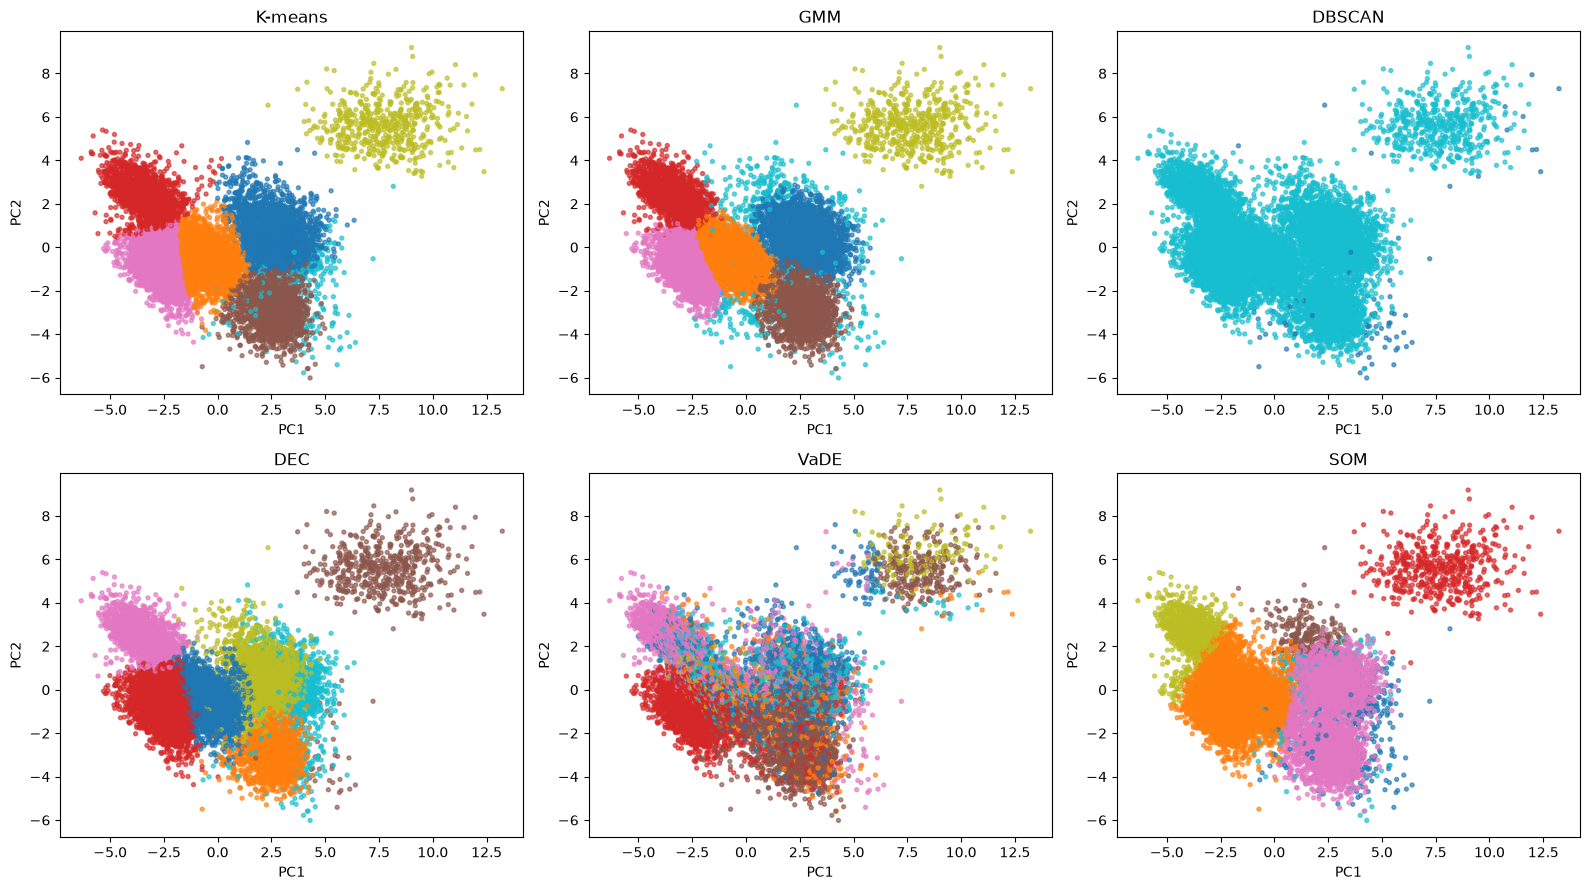

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16,9))
for ax, (name, labels) in zip(axes.flat, all_labels.items()):
    ax.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap="tab10", s=8, alpha=.65)
    ax.set_title(name); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
for ax in axes.flat[len(all_labels):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Что показывает визуальное сравнение

Все алгоритмы отображены в единой PCA-проекции, поэтому различия на рисунках отражают именно различия в присвоенных метках, а не разные координаты объектов.

Визуально наиболее отчётливо отделяется область, соответствующая крупной обособленной группе, тогда как в центральных областях несколько разновидностей пересекаются. Это помогает объяснить, почему даже лучшие алгоритмы не достигают полного совпадения с исходной разметкой.

Сравнивать методы только по цветным картинкам нельзя: визуализация двумерная, тогда как кластеризация выполнялась в 16-мерном пространстве либо в латентном представлении. Поэтому график используется как иллюстрация к численным метрикам, а не как самостоятельное доказательство превосходства алгоритма.

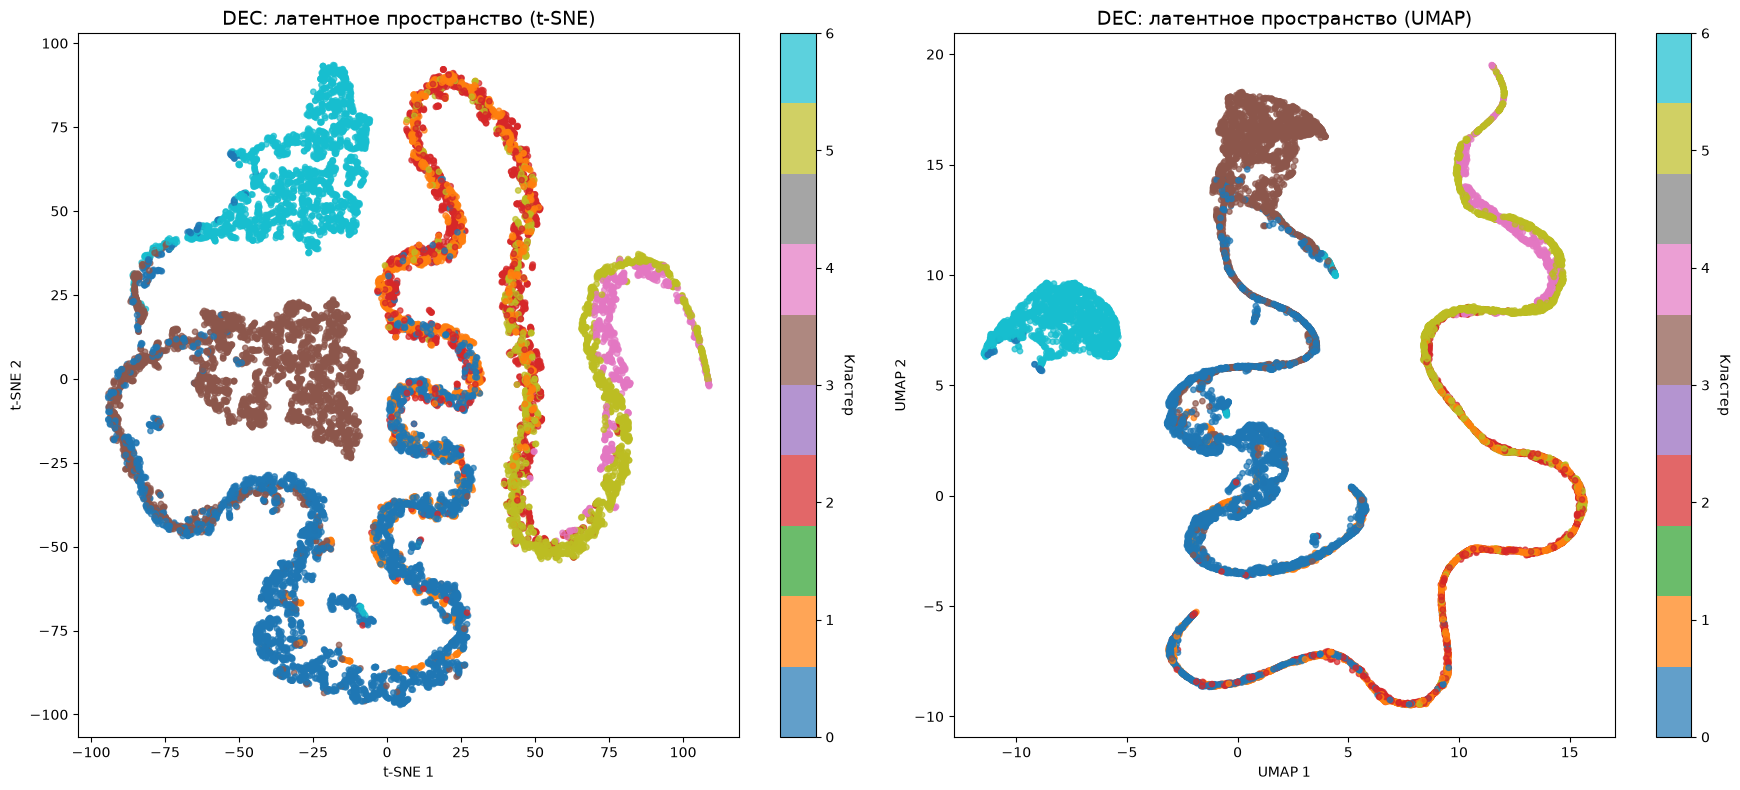

In [60]:
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
z_dec_np = z_dec.cpu().numpy()
z_dec_2d = tsne.fit_transform(z_dec_np)

reducer = umap.UMAP(n_components=2, random_state=SEED)
z_dec_umap = reducer.fit_transform(z_dec_np)


fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, data, title, xlabel, ylabel in zip(
    axes,
    [z_dec_2d, z_dec_umap],
    ["DEC: латентное пространство (t-SNE)", "DEC: латентное пространство (UMAP)"],
    ["t-SNE 1", "UMAP 1"],
    ["t-SNE 2", "UMAP 2"],
):
    scatter = ax.scatter(data[:, 0], data[:, 1],
                         c=dec_labels, cmap="tab10", s=15, alpha=0.7)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label("Кластер", rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

Алгоритм глубокой кластеризации DEC сформировал осмысленную структуру в латентном пространстве, выделив один четко разделенный кластер (кластер 6). Однако большинство кластеров перекрываются, что указывает на неидеальное разделение данных и наличие сложных переходных зон. Кластеры имеют сложную, «извилистую» геометрию, затрудняя интерпретацию. Вероятно, заданное количество кластеров (k=7) не оптимально, и требуется корректировка гиперпараметров или пересмотр числа кластеров для достижения более чистого разделения.

## 15. Содержательная интерпретация состава кластеров

Для метода с наибольшим ARI строится таблица долей исходных классов внутри каждого кластера. Это позволяет понять не только численное качество, но и характер найденных групп.

Если кластер почти полностью состоит из одного исходного класса, его можно интерпретировать как хорошо выделенную группу. Если в кластере смешаны несколько классов, это может отражать сходство геометрических характеристик или недостаточную разделимость соответствующих разновидностей.

Таблица состава кластеров является внешним аналитическим инструментом: она не означает, что исходные метки участвовали в обучении модели.

In [ ]:
best_method = results["ARI"].idxmax()
best_labels = all_labels[best_method]
cluster_table = pd.crosstab(pd.Series(best_labels, name="Кластер"),
                            pd.Series(label_encoder.inverse_transform(y), name="Исходный класс"),
                            normalize="index")
print("Лучший метод по ARI:", best_method)
display(cluster_table.round(3))

Лучший метод по ARI: GMM


Исходный класс,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Кластер,,,,,,,
0,0.380,0.000,0.608,0.000,0.009,0.000,0.002
1,0.007,0.000,0.003,0.195,0.009,0.031,0.755
2,0.000,0.000,0.001,0.048,0.000,0.936,0.015
3,0.003,0.000,0.022,0.001,0.929,0.000,0.045
4,0.000,0.000,0.000,0.964,0.002,0.006,0.029
5,0.000,1.000,0.000,0.000,0.000,0.000,0.000
6,0.496,0.003,0.066,0.128,0.177,0.078,0.052


### Интерпретация состава кластеров GMM

GMM выбран для подробного анализа, поскольку он показал наибольшие значения ARI и NMI. Таблица содержит доли исходных классов внутри каждого найденного кластера.

Некоторые группы выделены достаточно чисто:

- кластер 5 полностью состоит из объектов класса `BOMBAY`;
- кластер 3 преимущественно соответствует `HOROZ` (92,9%);
- кластер 2 преимущественно соответствует `SEKER` (93,6%);
- кластер 4 преимущественно соответствует `DERMASON` (96,4%);
- кластер 1 в основном соответствует `SIRA` (75,5%).

В то же время кластер 0 объединяет преимущественно `CALI` (60,8%) и `BARBUNYA` (38,0%), а кластер 6 содержит смешанный состав нескольких классов. Это указывает на то, что геометрические признаки позволяют хорошо отделить некоторые разновидности, но другие имеют пересекающиеся области признакового пространства.

**Содержательная интерпретация.** GMM успешно обнаруживает несколько достаточно однородных групп, однако не все исходные разновидности соответствуют отдельным компактным кластерам. Смешанные кластеры могут быть связаны как с близостью геометрических характеристик, так и с тем, что модель описывает данные гауссовыми компонентами, а реальные распределения могут быть сложнее.

## 16. Ограничения эксперимента и направления улучшения

Полученные результаты позволяют сравнить несколько подходов, однако эксперимент имеет ограничения, которые важно явно указать.

1. **Подбор гиперпараметров не является полным поиском.** В текущем запуске зафиксированы латентная размерность 10, число кластеров 7, скорость обучения `1e-3` для глубоких моделей и заданные параметры SOM/DBSCAN. Поэтому корректно говорить о сравнении выбранных конфигураций, но не об исчерпывающей оптимизации гиперпараметров.
2. **Результат DBSCAN зависит от плотности.** Следующим шагом может быть подбор `eps` и `min_samples`, а также проверка расстояний в пространстве PCA.
3. **VaDE реализован в учебном упрощённом виде.** Для строгого воспроизведения оригинального метода необходимо использовать соответствующую ELBO и корректную процедуру инициализации параметров смеси.
4. **PCA используется для визуализации.** Она не заменяет анализ кластеров в исходном пространстве и может скрывать локальные особенности данных.
5. **Устойчивость глубоких моделей требует повторных запусков.** Для оценки устойчивости разбиения рекомендуется провести серию запусков моделей (DEC, VaDE, SOM) с различными значениями `random_state` (например, 42, 123, 456) и рассчитать попарный ARI между полученными разбиениями. В текущем эксперименте фиксация `SEED=42` обеспечивает воспроизводимость, но не доказывает глобальную устойчивость глубоких методов к инициализации весов.

Эти ограничения не отменяют полученных результатов, но задают границы их интерпретации.

## 17. Итоговые выводы

В ходе работы был исследован набор Dry Bean Dataset, включающий 13 611 исходных наблюдений и 16 числовых геометрических признаков. После удаления 68 дубликатов для моделирования осталось 13 543 объекта. Пропусков в исходной таблице не было; признаки стандартизированы, а исходный столбец `Class` не использовался при обучении.

Визуальный анализ PCA показал, что часть разновидностей фасоли формирует относительно обособленные области, однако некоторые классы перекрываются. Это ограничивает возможность получить полностью чистое разбиение только на основе имеющихся геометрических признаков.

Среди рассмотренных алгоритмов лучший результат по внешним метрикам показал **GMM** (ARI = 0,681; NMI = 0,732). K-means оказался близок по внешнему качеству и показал лучшие внутренние метрики Silhouette и Davies–Bouldin. Среди глубоких подходов наиболее успешным оказался **DEC** (ARI = 0,580; NMI = 0,643), тогда как SOM показал более умеренное качество, а упрощённая VaDE-подобная модель — низкое соответствие исходным классам.

Анализ состава кластеров GMM показал, что некоторые разновидности (`BOMBAY`, `HOROZ`, `SEKER`, `DERMASON`) выделяются достаточно чисто. Другие группы, прежде всего `CALI` и `BARBUNYA`, частично смешиваются, что согласуется с перекрытием областей на PCA-проекции.

**Общий вывод:** применение глубокой кластеризации для Dry Bean Dataset методически оправдано как способ изучить нелинейное латентное представление данных и сравнить различные стратегии обучения без учителя. Однако в проведённом эксперименте глубокие модели не превзошли классические методы. Для данного набора GMM оказался наиболее удачным компромиссом по внешнему соответствию исходным классам, а DEC продемонстрировал, что глубокое представление может быть полезным, но само по себе не гарантирует улучшения кластеризации.

Для окончательного подтверждения выводов о настройках моделей необходим дополнительный систематический подбор гиперпараметров и повторные запуски с различными значениями random_state (например, 42, 123, 456) для оценки устойчивости разбиений (например, через попарный ARI). В текущем эксперименте фиксация SEED=42 обеспечивает воспроизводимость, но не доказывает глобальную устойчивость глубоких методов к инициализации весов.